In [2]:
import matplotlib.pyplot as plt
import cv2
import numpy as np
from sklearn.cluster import KMeans

In [3]:
img=cv2.imread("RYANGOSNIGHT2.jpg")
img=cv2.cvtColor(img,cv2.COLOR_BGR2RGB)
print(img.shape)

(853, 2048, 3)


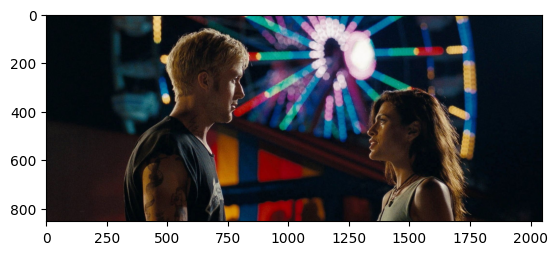

In [4]:
plt.imshow(img)
plt.show()

In [5]:
X=img.reshape((-1,3))
print(X.shape)

(1746944, 3)


In [6]:
k=5
model=KMeans(n_clusters=k)
model.fit(X)

,n_clusters,5
,init,'k-means++'
,n_init,'auto'
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,None
,copy_x,True
,algorithm,'lloyd'


In [7]:
#to get dominant vibrant color
def get_vibrant(img,min_sat=50,min_val=70,k=5):
    img_hsv=cv2.cvtColor(img,cv2.COLOR_BGR2HSV)
    pixel_hsv=img_hsv.reshape((-1,3))
    mask=(pixel_hsv[:,1]>=min_sat) & (pixel_hsv[:,2]>=min_val)
    max_pixel_hsv=100000
    colourfulpix=X[mask]
    if len(colourfulpix)>max_pixel_hsv:
        np.random.shuffle(colourfulpix)
        pixettofit=colourfulpix[:max_pixel_hsv]
    else:
        pixettofit=colourfulpix
    kmeans=KMeans(n_clusters=k,n_init=10,random_state=0)
    kmeans.fit(pixettofit)
    vibrant_color=kmeans.cluster_centers_.astype('uint8')
    return vibrant_color,kmeans

In [8]:
centroids=model.cluster_centers_

In [9]:
print(centroids)

[[ 14.78558436  17.49481681  23.38976345]
 [216.70352876 197.01928898 198.92462819]
 [ 90.46452968  45.94582205  37.94293267]
 [ 17.84519903  90.85432308 122.951504  ]
 [152.75634727 124.433348   106.63023701]]


In [10]:
colors=np.array(centroids,dtype='uint8')

In [11]:
print(colors)

[[ 14  17  23]
 [216 197 198]
 [ 90  45  37]
 [ 17  90 122]
 [152 124 106]]


[14 17 23]
[216 197 198]
[90 45 37]
[ 17  90 122]
[152 124 106]


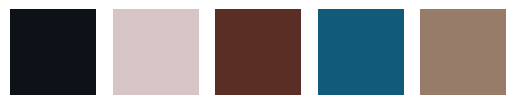

In [12]:
#Color Patch(100,100,3)
i=1
for color in colors:
    print(color)
    plt.subplot(1,k,i)
    plt.axis('off')
    i=i+1
    mat=np.full((100,100,3),color,dtype='uint8')
    plt.imshow(mat)
plt.show()

In [15]:
vibrant_palette,kmeans=get_vibrant(img,min_sat=50,min_val=70,k=5)

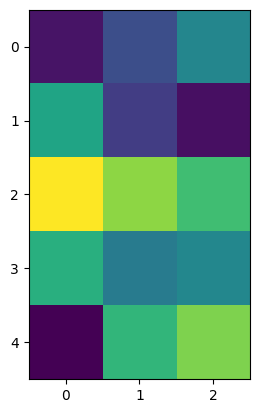

In [16]:
plt.imshow(vibrant_palette)
plt.show()

[23 55 92]
[113  45  21]
[184 155 132]
[121  85  93]
[ 14 126 151]


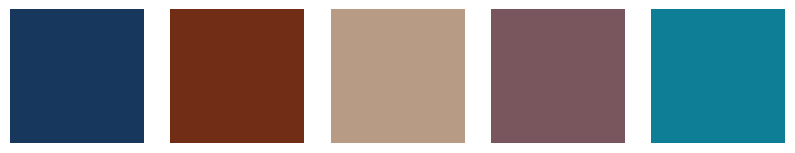

In [17]:
#Color Patch(100,100,3) --> Red Color
k=len(vibrant_palette)
plt.figure(figsize=(k*2,2))
i=1
for color in vibrant_palette:
    print(color)
    plt.subplot(1,k,i)
    plt.axis('off')
    i=i+1
    mat=np.full((100,100,3),color,dtype='uint8')
    plt.imshow(mat)
plt.show()

In [18]:
np.unique(model.labels_)

array([0, 1, 2, 3, 4])

In [19]:
model.labels_.shape

(1746944,)

In [20]:
newImg=np.zeros((X.shape),dtype='uint8')
print(newImg.shape)

(1746944, 3)


In [21]:
for i in range(newImg.shape[0]):
    newImg[i]=colors[model.labels_[i]]

In [22]:
newImg=newImg.reshape(img.shape)

In [23]:
print(newImg.shape)

(853, 2048, 3)


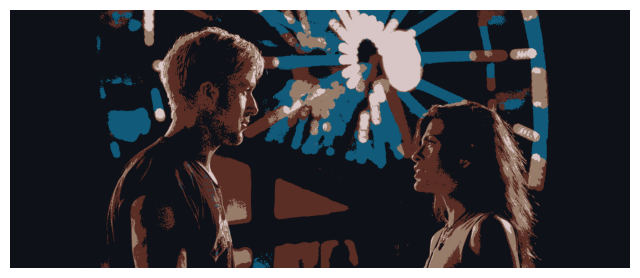

In [31]:
plt.figure(figsize=(8,8))
plt.imshow(newImg)
plt.axis('off')
plt.show()

In [25]:
apl=kmeans.predict(X)

In [26]:
newVIM=vibrant_palette[apl]

In [27]:
RecImg=newVIM.reshape(img.shape)

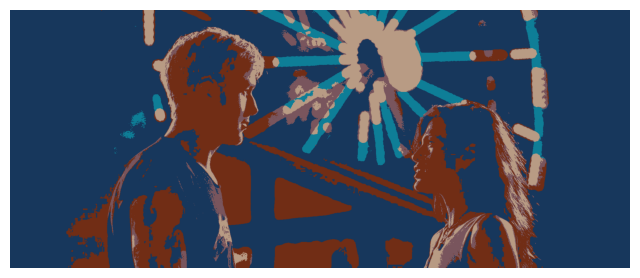

In [30]:
plt.figure(figsize=(8,8))
plt.imshow(RecImg)
plt.axis('off')
plt.show()

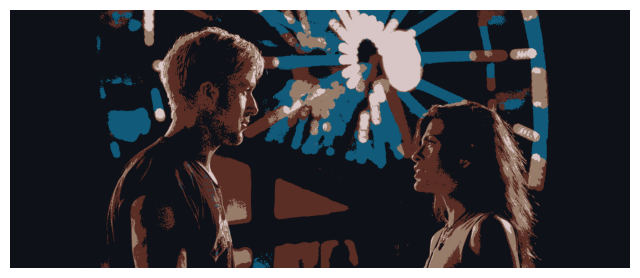

In [33]:
#Dominant Color Extraction
plt.figure(figsize=(8,8))
plt.imshow(newImg)
plt.axis('off')
plt.show()